[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Time-Series-Analysis/blob/main/Quantlets/Ch_11/TSA_ch11_seminar/TSA_ch11_seminar.ipynb)

# Time Series Analysis — Seminar 11: Foundation models for time series

*Seminar notebook (self-study chapter). Daniel Traian Pele, Bucharest University of Economic Studies.*

- No foundation model is run here: the notebook reads the saved forecast scores of Lecture 11 (`ch11_backtest.csv`, `ch11_abs_err.json`, `ch11_numbers.json`) from the repository.
- [Solved] tasks: full solution here and in the slides; [Proposed] tasks: write your own code in the empty cell.
- The seminar is for practice and is not graded; the solutions of [Proposed] tasks are discussed in class.

> Quantlet `TSA_ch11_seminar`: student version of the Seminar 11 notebook. Solved exercises (A1, A3, B1, B3) are shown with code and output; the proposed exercises (A2, A4, B2, C1) are not solved here (an empty code cell where they need code).

> The solutions are discussed in the seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/TSA/Chapter_11'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [ ]:
import os
import re
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from scipy import optimize
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

## Chart style

- Transparent background, legend below the plot, course palette.

In [ ]:
# Palette (RGB values of latex/preamble.tex)
MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Orange = '#E67E22'
Purple = '#8E44AD'
Teal = '#17A2B8'
Crimson = '#DC3545'
DarkText = '#1F2A44'          # text, axes and ticks (dark navy, not grey)

PALETTE = [MainBlue, IDAred, Forest, Amber, Purple, Orange, Teal, Crimson]
# fixed colours for the series used in several chapters
COL = {'sp500': MainBlue, 'bet': IDAred, 'bettr': Orange, 'dax': Teal, 'btc': Amber, 'eth': Crimson,
       'eurron': Forest, 'gold': Purple, 'vix': Crimson, 'stoxx50': Forest, 'ndx': Teal}


def apply():
    """Set the course style for matplotlib."""
    rc = plt.rcParams
    rc['figure.facecolor'] = 'none'
    rc['axes.facecolor'] = 'none'
    rc['savefig.facecolor'] = 'none'
    rc['savefig.transparent'] = True
    rc['axes.grid'] = False
    rc['font.family'] = 'sans-serif'
    rc['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
    # default size about 7 inches wide (as in MFM); a chart is shown 11-13 cm wide on a slide, so these font sizes
    # give 7-9 pt text there. Multi-panel charts should stay near 7-7.6 inches wide: at 10-11 inches the axis
    # text drops to about 5 pt on the slide.
    rc['figure.figsize'] = (7.0, 3.4)
    rc['font.size'] = 12
    rc['axes.labelsize'] = 13
    rc['axes.titlesize'] = 13
    rc['xtick.labelsize'] = 11.5
    rc['ytick.labelsize'] = 11.5
    rc['legend.fontsize'] = 11
    rc['axes.spines.top'] = False
    rc['axes.spines.right'] = False
    rc['axes.linewidth'] = 0.6
    rc['lines.linewidth'] = 1.4
    rc['legend.facecolor'] = 'none'
    rc['legend.framealpha'] = 0
    rc['legend.frameon'] = False
    for k in ('text.color', 'axes.labelcolor', 'axes.edgecolor', 'xtick.color', 'ytick.color', 'axes.titlecolor'):
        rc[k] = DarkText
    rc['axes.prop_cycle'] = mpl.cycler(color=PALETTE)
    _remember_tight_layout()


def _remember_tight_layout():
    """Figure.tight_layout also stores its arguments on the figure, so that save_fig can re-apply the same layout
    after it has wrapped a label or changed the number of legend columns (see finalize)."""
    from matplotlib.figure import Figure
    if getattr(Figure.tight_layout, '_tsa', False):
        return
    orig = Figure.tight_layout

    def tight_layout(self, *a, **k):
        self._tsa_tight = (a, k)
        return orig(self, *a, **k)
    tight_layout._tsa = True
    Figure.tight_layout = tight_layout


def legend_outside_bottom(ax, ncol=2, y=-0.22, **kw):
    """Place the legend outside the plot, bottom centre (for a figure with several axes, pass the last one
    or use fig.legend with the same arguments)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=3, y=-0.02):
    """One legend for a whole figure (several panels), below the panels."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h)
                    labels.append(l)
    return fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def _is_grey(c, tol=0.06):
    try:
        r, g, b = to_rgb(c)
    except ValueError:
        return False
    return max(r, g, b) - min(r, g, b) < tol and 0.25 < (r + g + b) / 3 < 0.95


def check_no_grey(fig):
    """House rule: no grey series and no grey text. Raises ValueError listing the offending elements."""
    bad = []
    for ax in fig.axes:
        for ln in ax.get_lines():
            if not ln.get_label().startswith('_') and _is_grey(ln.get_color()):
                bad.append(f'line {ln.get_label()!r}')
        for coll in ax.collections:
            fc = coll.get_facecolor()
            if len(fc) and coll.get_label() and not coll.get_label().startswith('_') and _is_grey(fc[0][:3]):
                bad.append(f'series {coll.get_label()!r}')
        for t in ax.texts + [ax.title, ax.xaxis.label, ax.yaxis.label]:
            if t.get_text() and _is_grey(t.get_color()):
                bad.append(f'text {t.get_text()[:30]!r}')
    if bad:
        raise ValueError('grey elements: ' + ', '.join(bad))


def save_fig(name, out_dir=None, show=True):
    """Save the figure as transparent PDF and PNG (OUT_DIR if defined, else the current folder), then show it."""
    d = out_dir or globals().get('OUT_DIR', '.')
    plt.savefig(os.path.join(d, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(d, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    if show:
        plt.show()
    plt.close()


apply()
# the chapter scripts call the style as st.<name> (import tsa_style as st): the same names here
import types
st = types.SimpleNamespace(COL=COL, PALETTE=PALETTE, MainBlue=MainBlue, IDAred=IDAred, Forest=Forest, Amber=Amber,
                           Orange=Orange, Purple=Purple, Teal=Teal, Crimson=Crimson, DarkText=DarkText, apply=apply, legend_outside_bottom=legend_outside_bottom,
                           fig_legend_bottom=fig_legend_bottom, save_fig=save_fig, check_no_grey=check_no_grey)

## Data

- Daily market data from EODHD, saved in `data/market` of the TSA repository; EUR/RON is the official BNR reference rate.
- Macroeconomic series: FRED (St. Louis Fed), Eurostat and the classic data sets of statsmodels.
- Returns in %: $r_t = 100(\ln P_t - \ln P_{t-1})$; each series on its own calendar.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'          # last day of the saved data

# name -> (symbol, label, group, field, default start)
SERIES = {
    # equity indices
    'sp500':    ('GSPC.INDX',     'S&P 500',               'Equity', 'close', '2000-01-01'),
    'ndx':      ('NDX.INDX',      'Nasdaq 100',            'Equity', 'close', '2000-01-01'),
    'dax':      ('GDAXI.INDX',    'DAX',                   'Equity', 'close', '2000-01-01'),
    'stoxx50':  ('STOXX50E.INDX', 'Euro Stoxx 50',         'Equity', 'close', '2000-01-01'),
    'nikkei':   ('N225.INDX',     'Nikkei 225',            'Equity', 'close', '2000-01-01'),
    'bet':      ('BET',           'BET',                   'Equity', 'close', '2000-01-01'),
    'bettr':    ('BETTR.INDX',    'BET-TR',                'Equity', 'close', '2014-09-23'),
    'betxt':    ('BETXT.INDX',    'BET-XT',                'Equity', 'close', '2011-08-12'),
    'betfi':    ('BETFI.INDX',    'BET-FI',                'Equity', 'close', '2012-01-25'),
    'wig20':    ('WIG20.INDX',    'WIG20',                 'Equity', 'close', '2000-01-01'),
    'bux':      ('BUX.INDX',      'BUX',                   'Equity', 'close', '2000-01-01'),
    'px':       ('PX.INDX',       'PX',                    'Equity', 'close', '2000-01-01'),
    'vix':      ('VIX.INDX',      'VIX',                   'Volatility', 'close', '2000-01-01'),
    # ETFs (adjusted close)
    'spy':      ('SPY.US',        'SPY',                   'ETF', 'adjusted_close', '2000-01-01'),
    'tlt':      ('TLT.US',        'TLT (US Treasuries 20y+)', 'ETF', 'adjusted_close', '2002-07-30'),
    'gld':      ('GLD.US',        'GLD (gold ETF)',        'ETF', 'adjusted_close', '2004-11-18'),
    'tvbetetf': ('TVBETETF.RO',   'TVBETETF',              'ETF', 'adjusted_close', '2015-06-12'),
    # Bucharest Stock Exchange (adjusted close)
    'tlv':      ('TLV.RO',        'Banca Transilvania',    'Stock', 'adjusted_close', '2000-01-01'),
    'snp':      ('SNP.RO',        'OMV Petrom',            'Stock', 'adjusted_close', '2001-09-04'),
    'brd':      ('BRD.RO',        'BRD',                   'Stock', 'adjusted_close', '2001-01-16'),
    'tgn':      ('TGN.RO',        'Transgaz',              'Stock', 'adjusted_close', '2008-01-25'),
    'sng':      ('SNG.RO',        'Romgaz',                'Stock', 'adjusted_close', '2013-11-12'),
    'snn':      ('SNN.RO',        'Nuclearelectrica',      'Stock', 'adjusted_close', '2013-11-04'),
    'h2o':      ('H2O.RO',        'Hidroelectrica',        'Stock', 'adjusted_close', '2023-07-12'),
    # US stocks (adjusted close)
    'aapl':     ('AAPL.US',       'Apple',                 'Stock', 'adjusted_close', '2000-01-01'),
    'msft':     ('MSFT.US',       'Microsoft',             'Stock', 'adjusted_close', '2000-01-01'),
    'nvda':     ('NVDA.US',       'NVIDIA',                'Stock', 'adjusted_close', '2000-01-01'),
    'jpm':      ('JPM.US',        'JPMorgan Chase',        'Stock', 'adjusted_close', '2000-01-01'),
    # crypto (close, 7 days a week)
    'btc':      ('BTC-USD.CC',    'Bitcoin',               'Crypto', 'close', '2014-09-17'),
    'eth':      ('ETH-USD.CC',    'Ethereum',              'Crypto', 'close', '2015-08-07'),
    'sol':      ('SOL-USD.CC',    'Solana',                'Crypto', 'close', '2020-04-11'),
    'usdt':     ('USDT-USD.CC',   'Tether (USDT)',         'Crypto', 'close', '2015-02-26'),
    # FX and commodities
    'eurron':   ('REF:EUR',       'EUR/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'usdron':   ('REF:USD',       'USD/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'eurron_eodhd': ('EURRON.FOREX', 'EUR/RON (EODHD)',    'FX', 'close', '2005-07-01'),
    'eurusd':   ('EURUSD.FOREX',  'EUR/USD',               'FX', 'close', '2002-05-06'),
    'gold':     ('XAUUSD.FOREX',  'Gold (XAU/USD)',        'Commodity', 'close', '2000-01-01'),
    # government bond yields (close, % p.a.)
    'us10y':    ('US10Y.GBOND',   'US 10Y yield',          'Yield', 'close', '2000-01-01'),
    'de10y':    ('DE10Y.GBOND',   'Germany 10Y yield',     'Yield', 'close', '2007-03-28'),
    'ro10y':    ('RO10Y.GBOND',   'Romania 10Y yield',     'Yield', 'close', '2007-08-17'),
}
LABELS = {k: v[1] for k, v in SERIES.items()}
_CACHE = {}


def read_market(symbol):
    """Daily table of one symbol: local copy of the course data, otherwise the TSA repository on GitHub."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname) if MARKET_DIR else ''
    src = path if path and os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official BNR reference rate (RON per unit of currency), from the public yearly XML archives."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(max(int(start[:4]), 2005), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}"(?: multiplier="\d+")?>([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END, field=None):
    """Daily closing price of a named series, cleaned with the course conventions."""
    symbol, label, group, field0, start0 = SERIES[name]
    start, field = start or start0, field or field0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    t = read_market(symbol)
    s = (t[field] if field in t.columns else t['close']).loc[start:end]
    s = pd.to_numeric(s, errors='coerce').dropna()
    if group != 'Yield':
        s = s[s > 0]
    if group != 'Crypto':
        s = s[s.index.dayofweek < 5]          # no weekend quotes
        s = s[s.diff() != 0]                  # no holidays filled with the previous price
    s.index.name = 'date'
    return s.rename(name)


def load_ohlc(name, start=None, end=END):
    """Open, high, low, close (and volume) of a series with OHLC data (range-based volatility estimators)."""
    symbol, _, group, _, start0 = SERIES[name]
    t = read_market(symbol).loc[start or start0:end]
    cols = [c for c in ('open', 'high', 'low', 'close', 'volume') if c in t.columns]
    t = t[cols].dropna()
    if group != 'Crypto':
        t = t[t.index.dayofweek < 5]
    return t[(t[['open', 'high', 'low', 'close']] > 0).all(axis=1)] if 'open' in cols else t


def log_returns(name, start=None, end=END, pct=True):
    """Daily log returns r_t = ln P_t - ln P_{t-1} (in % by default), on the series' own calendar."""
    r = np.log(load_close(name, start, end)).diff().dropna()
    return (100 * r if pct else r).rename(name)


def simple_returns(name, start=None, end=END, pct=True):
    """Daily simple returns R_t = P_t / P_{t-1} - 1 (in % by default)."""
    r = load_close(name, start, end).pct_change().dropna()
    return (100 * r if pct else r).rename(name)


def load_panel(names, start=None, end=END, kind='close'):
    """Several series aligned on date: kind = 'close' or 'returns' (NaN where a market does not trade)."""
    f = load_close if kind == 'close' else log_returns
    return pd.concat([f(n, start, end) for n in names], axis=1)


def periods_per_year(r):
    """Average number of observations per calendar year (the actual frequency of the series)."""
    years = (r.index[-1] - r.index[0]).days / 365.25
    return len(r) / years


def read_fred(ids, start=None, end=None):
    """FRED series (St. Louis Fed) from the public fredgraph CSV, e.g. read_fred('UNRATE') or
    read_fred(['GDPC1', 'CPIAUCSL']). Returns a Series (one id) or a DataFrame (several ids)."""
    one = isinstance(ids, str)
    ids = [ids] if one else list(ids)
    out = []
    for sid in ids:
        key = ('fred', sid)
        if key not in _CACHE:
            url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}'
            t = pd.read_csv(url, index_col=0, parse_dates=True, na_values='.')
            _CACHE[key] = pd.to_numeric(t.iloc[:, 0], errors='coerce').rename(sid)
        out.append(_CACHE[key])
    df = pd.concat(out, axis=1).loc[start:end]
    df.index.name = 'date'
    return df.iloc[:, 0].dropna() if one else df


def _eurostat_period(p):
    p = str(p)
    if '-Q' in p:
        y, q = p.split('-Q')
        return pd.Timestamp(int(y), 3 * int(q) - 2, 1)
    if '-' in p and len(p) == 7:
        return pd.Timestamp(p + '-01')
    if len(p) == 4:
        return pd.Timestamp(int(p), 1, 1)
    return pd.Timestamp(p)


def read_eurostat(dataset, key, start=None):
    """One Eurostat series from the public SDMX 2.1 API (SDMX-CSV), e.g. Romanian quarterly real GDP,
    seasonally and calendar adjusted, chain-linked volumes (2010) in million EUR:
        read_eurostat('namq_10_gdp', 'Q.CLV10_MEUR.SCA.B1GQ.RO')
    `key` is the dot-separated series key of the dataset (dimensions in the order of the dataset)."""
    url = (f'https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/{dataset}/{key}?format=SDMX-CSV'
           + (f'&startPeriod={start}' if start else ''))
    ck = ('eurostat', url)
    if ck not in _CACHE:
        t = pd.read_csv(url)
        s = pd.Series(pd.to_numeric(t['OBS_VALUE'], errors='coerce').values,
                      index=[_eurostat_period(p) for p in t['TIME_PERIOD']], name=f'{dataset}:{key}')
        s.index.name = 'date'
        _CACHE[ck] = s.sort_index().dropna()
    return _CACHE[ck]


def load_statsmodels(name):
    """Classic data sets shipped with statsmodels (offline): 'sunspots' (yearly, 1700-2008), 'co2' (weekly,
    Mauna Loa, 1958-2001), 'macrodata' (US quarterly macro, 1959-2009), 'nile' (yearly Nile flow, 1871-1970)."""
    import statsmodels.api as sm
    if name == 'sunspots':
        d = sm.datasets.sunspots.load_pandas().data
        s = d.set_index(pd.to_datetime(d['YEAR'].astype(int).astype(str)))['SUNACTIVITY']
        s.index.name = 'date'
        return s.rename('sunspots')
    if name == 'co2':
        return sm.datasets.co2.load_pandas().data['co2'].rename('co2')
    if name == 'macrodata':
        d = sm.datasets.macrodata.load_pandas().data
        d.index = pd.period_range('1959Q1', periods=len(d), freq='Q').to_timestamp()
        d.index.name = 'date'
        return d
    if name == 'nile':
        d = sm.datasets.nile.load_pandas().data
        s = d.set_index(pd.to_datetime(d['year'].astype(int).astype(str)))['volume']
        s.index.name = 'date'
        return s.rename('nile')
    raise KeyError(f'unknown statsmodels data set: {name}')

## Seminar functions

- Helpers of Chapter 11 (`get_series`, `snaive_q`, `pinball`, `wql_parts`, `mase`, `summarise`) and the seminar functions: `backtest_rows`, `abs_errors`, `a1_pinball_hour`, `a3_wql_origins`, `b1_inflation`, `dm_test`, `b3_dm`.

In [ ]:
import time
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
SEED = 2026
LEVELS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
FM = {'Chronos-Bolt tiny': 'amazon/chronos-bolt-tiny', 'Chronos-Bolt small': 'amazon/chronos-bolt-small', 'Chronos-2': 'amazon/chronos-2'}
RELEASE = {'Chronos-Bolt tiny': '2024-11-25', 'Chronos-Bolt small': '2024-11-25', 'Chronos-2': '2025-10-30'}
MODELS = ['Seasonal naive', 'ETS', 'ARIMA', 'Chronos-Bolt tiny', 'Chronos-Bolt small', 'Chronos-2']
LOAD_FILE = 'ch4_ro_load_hourly.csv'
LOAD_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/Quantlets/Ch_04/ch4_ro_load_hourly.csv'
EVAL_SERIES = {'load': ('RO electricity load, hourly', 168, 48, '2025-07-07', 168, 2048), 'ip': ('RO industrial production, monthly', 12, 12, '2016-01-01', 1, 2048), 'gdp': ('RO real GDP, quarterly', 4, 4, '2012-01-01', 1, 2048), 'infl': ('RO inflation, monthly', 12, 12, '2016-01-01', 1, 2048), 'unemp': ('RO unemployment rate, monthly', 1, 12, '2016-01-01', 1, 2048), 'eurron': ('EUR/RON, daily', 1, 20, '2016-01-04', 20, 2048), 'retail': ('US retail sales, monthly', 12, 12, '2016-01-01', 1, 2048)}
SHORT = {'load': 'RO load', 'ip': 'RO ind. prod.', 'gdp': 'RO GDP', 'infl': 'RO inflation', 'unemp': 'RO unemployment', 'eurron': 'EUR/RON', 'retail': 'US retail'}
CONTEXTS = [96, 192, 336, 672, 1344, 2048]
_PIPES = {}
COLORS = {'Seasonal naive': st.Amber, 'ETS': st.Forest, 'ARIMA': st.Purple, 'Chronos-Bolt tiny': st.Teal, 'Chronos-Bolt small': st.MainBlue, 'Chronos-2': st.IDAred, 'actual': st.DarkText}
HERE = "."
SAVED_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/Quantlets/Ch_11/'
FAN_ORIGIN, FAN_HOUR = '2026-06-22', 24
IP_ORIGIN = '2025-08-01'
WQL_ORIGINS = 4
INFL_SPLIT = '2021-01-01'
ROLL = 24


def save(name, save_it=True):
    if save_it:
        st.check_no_grey(plt.gcf())
        st.save_fig(name)
    else:
        plt.show()


def ro_load():
    """Hourly electricity load of Romania (GW), ENTSO-E extract of Chapter 4, Romanian winter time (UTC+2);
    isolated one-hour glitches (more than 30% away from both neighbours) are interpolated."""
    s = None
    local = [os.path.join(HERE, '..', 'Ch_04', LOAD_FILE)] + [os.path.join(d, 'Quantlets', 'Ch_04', LOAD_FILE)
                                                            for d in ('.', '..', '../..', '../../..')]
    for src in [p for p in local if os.path.exists(p)] + [LOAD_RAW]:
        try:
            s = pd.read_csv(src, index_col=0, parse_dates=True).iloc[:, 0]
            break
        except Exception:
            continue
    s.index = s.index + pd.Timedelta(hours=2)
    s = s.reindex(pd.date_range(s.index[0], s.index[-1], freq='h'))
    r = s / ((s.shift(1) + s.shift(-1)) / 2)
    s[(r < 0.7) | (r > 1.3)] = np.nan
    return (s.interpolate() / 1000).rename('load')


def get_series(key):
    """The seven evaluation series (levels, as published)."""
    if key == 'load':
        return ro_load()
    if key == 'ip':      # industrial production (mining, manufacturing, energy), 2021 = 100, not seasonally adjusted
        return read_eurostat('sts_inpr_m', 'M.PRD.B-D.NSA.I21.RO').rename('ip')
    if key == 'gdp':     # real GDP, chain-linked volumes 2010, million EUR, not seasonally adjusted
        return (read_eurostat('namq_10_gdp', 'Q.CLV10_MEUR.NSA.B1GQ.RO') / 1000).rename('gdp')
    if key == 'infl':    # monthly inflation, 100 * log change of the HICP, in %
        p = read_eurostat('prc_hicp_minr', 'M.I15.TOTAL.RO')
        return (100 * np.log(p).diff()).dropna().loc['2000':].rename('infl')
    if key == 'unemp':   # unemployment rate, seasonally adjusted, % of the labour force
        return read_eurostat('une_rt_m', 'M.SA.TOTAL.PC_ACT.T.RO').rename('unemp')
    if key == 'eurron':  # BNR reference rate
        return load_close('eurron').rename('eurron')
    if key == 'retail':  # US retail sales excluding food services, not seasonally adjusted, billion USD
        return (read_fred('RSXFSN') / 1000).rename('retail')
    raise KeyError(key)


def chronos_pipeline(name):
    """Load a Chronos model from Hugging Face (cached); None if the package or the download is not available."""
    if name in _PIPES:
        return _PIPES[name]
    try:
        import torch
        from chronos import BaseChronosPipeline
        _PIPES[name] = BaseChronosPipeline.from_pretrained(FM[name], device_map='cpu', torch_dtype=torch.float32)
    except Exception as e:                       # graceful fallback: the statistical models still run
        print(f'   {name} not available ({type(e).__name__}): skipped')
        _PIPES[name] = None
    return _PIPES[name]


def fm_quantiles(name, contexts, h):
    """Zero-shot quantile forecasts (n, h, 9) at LEVELS from a list of 1-D context arrays; None if unavailable."""
    pipe = chronos_pipeline(name)
    if pipe is None:
        return None
    import torch
    x = [torch.tensor(np.asarray(c, dtype=np.float32)) for c in contexts]
    out = []
    for i in range(0, len(x), 64):
        q, _ = pipe.predict_quantiles(inputs=x[i:i + 64], prediction_length=h, quantile_levels=LEVELS)
        if isinstance(q, list):                   # Chronos-2 returns one tensor per series
            q = torch.stack([t.reshape(-1, h, len(LEVELS))[0] for t in q])
        out.append(q.float().numpy())
    return np.concatenate(out)


def n_parameters(name):
    pipe = chronos_pipeline(name)
    return None if pipe is None else int(sum(p.numel() for p in pipe.model.parameters()))


def normal_q(mean, sd):
    z = stats.norm.ppf(LEVELS)
    return np.asarray(mean)[:, None] + np.asarray(sd)[:, None] * z[None, :]


def snaive_q(y, h, m):
    """Seasonal naive: the value one season earlier; sd_h = sigma * sqrt(k + 1), k = number of whole seasons in h - 1
    (Hyndman and Athanasopoulos, FPP3, 5.5); sigma from the in-sample seasonal differences."""
    y = np.asarray(y, float)
    f = np.array([y[len(y) - m + (j % m)] for j in range(h)])
    e = y[m:] - y[:-m]
    sig = np.sqrt(np.mean(e ** 2))
    k = np.arange(h) // m
    return normal_q(f, sig * np.sqrt(k + 1))


def ets_q(y, h, m):
    """ETS with additive errors, damped additive trend and (if m > 1) additive seasonality; Normal quantiles."""
    y = pd.Series(np.asarray(y, float))
    seas = 'add' if 1 < m <= 52 else None
    r = ETSModel(y, error='add', trend='add', damped_trend=True, seasonal=seas,
                 seasonal_periods=m if seas else None).fit(disp=False, maxiter=200)
    p = r.get_prediction(start=len(y), end=len(y) + h - 1)
    return normal_q(np.asarray(p.predicted_mean), np.sqrt(np.asarray(p.forecast_variance)))


def select_arima(y, m):
    """Orders fixed once by AIC on the data before the first origin: (p, d, q) with p, q <= 2, d <= 1, and a seasonal
    MA(1) with one seasonal difference when 1 < m <= 52; for hourly load (m = 168) an ARMA on the weekly differences."""
    y = np.asarray(y, float)
    best = None
    for d in (0, 1):
        for p in range(3):
            for q in range(3):
                for D in ((0, 1) if 1 < m <= 52 else (0,)):
                    so = (0, D, 1, m) if D else (0, 0, 0, 0)
                    if m == 168:
                        so = (0, 1, 0, 168)
                        if d == 1:
                            continue
                    try:
                        a = SARIMAX(y, order=(p, d, q), seasonal_order=so, trend='c' if d + so[1] == 0 else 'n',
                                    simple_differencing=m == 168).fit(disp=False).aic
                    except Exception:
                        continue
                    if best is None or a < best[0]:
                        best = (a, (p, d, q), so)
    return best[1], best[2]


def arima_q(y, h, order, sorder):
    y = np.asarray(y, float)
    m = sorder[3]
    trend = 'c' if order[1] + sorder[1] == 0 else 'n'
    if m == 168:                                 # ARMA on y_t - y_{t-168}, then integrated back (h <= 168)
        r = SARIMAX(y, order=order, seasonal_order=sorder, trend=trend, simple_differencing=True).fit(disp=False)
        f = r.get_forecast(h)
        mean = y[len(y) - 168 + np.arange(h)] + np.asarray(f.predicted_mean)
        return normal_q(mean, np.sqrt(np.asarray(f.var_pred_mean)))
    r = SARIMAX(y, order=order, seasonal_order=sorder, trend=trend).fit(disp=False)
    f = r.get_forecast(h)
    return normal_q(np.asarray(f.predicted_mean), np.sqrt(np.asarray(f.var_pred_mean)))


def pinball(y, q, tau):
    """Quantile (pinball) loss: tau (y - q) if y >= q, (1 - tau)(q - y) otherwise."""
    u = np.asarray(y) - np.asarray(q)
    return np.maximum(tau * u, (tau - 1) * u)


def wql_parts(y, Q):
    """Numerator and denominator of the weighted quantile loss: sum over levels and steps of 2 * pinball, and
    sum |y| (times the number of levels). WQL = numerator / denominator, a discrete approximation of the CRPS."""
    num = sum(2 * pinball(y, Q[:, j], t).sum() for j, t in enumerate(LEVELS))
    return float(num), float(np.abs(y).sum() * len(LEVELS))


def mase(y, f, insample, m):
    """Mean absolute scaled error: MAE of the forecast over the in-sample MAE of the seasonal naive forecast."""
    x = np.asarray(insample, float)
    scale = np.mean(np.abs(x[m:] - x[:-m]))
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(f))) / scale)


def crps_normal(y, mu, sigma):
    """Closed-form CRPS of N(mu, sigma^2) at y (Gneiting and Raftery 2007)."""
    z = (y - mu) / sigma
    return float(sigma * (z * (2 * stats.norm.cdf(z) - 1) + 2 * stats.norm.pdf(z) - 1 / np.sqrt(np.pi)))


def origins_of(key, s):
    label, m, h, first, step, C = EVAL_SERIES[key]
    pos = np.arange(s.index.get_indexer([s.index[s.index >= pd.Timestamp(first)][0]])[0], len(s) - h + 1, step)
    return [int(p) for p in pos]


def backtest(key, max_origins=None, models=None, keep=False):
    """Rolling-origin evaluation of one series: at each origin every model forecasts h steps from the data up to the
    origin (at most C observations). Rows: origin, model, MASE, WQL parts, coverage of the 80% interval."""
    models = models or MODELS
    label, m, h, first, step, C = EVAL_SERIES[key]
    s = get_series(key)
    pos = origins_of(key, s)
    if max_origins:
        pos = pos[-max_origins:]
    order, sorder = select_arima(s.values[max(0, pos[0] - C):pos[0]][-1500:], m) if 'ARIMA' in models else (None, None)
    ctx = [s.values[max(0, p - C):p] for p in pos]
    Q = {}
    times = {}
    for name in [k for k in models if k in FM]:
        t0 = time.time()
        Q[name] = fm_quantiles(name, ctx, h)
        times[name] = (time.time() - t0) / len(ctx)
    for name in [k for k in models if k not in FM]:
        t0 = time.time()
        out = []
        for c in ctx:
            try:
                if name == 'Seasonal naive':
                    out.append(snaive_q(c, h, m))
                elif name == 'ETS':
                    out.append(ets_q(c[-2016:] if m == 168 else c, h, 24 if m == 168 else m))
                else:
                    out.append(arima_q(c, h, order, sorder))
            except Exception:
                out.append(snaive_q(c, h, m))
        Q[name] = np.array(out)
        times[name] = (time.time() - t0) / len(ctx)
    rows, store = [], {}
    for name, q in Q.items():
        if q is None:
            continue
        for i, p in enumerate(pos):
            y = s.values[p:p + h]
            num, den = wql_parts(y, q[i])
            rows.append({'series': key, 'origin': s.index[p], 'model': name, 'mase': mase(y, q[i][:, 4], ctx[i], m),
                         'wql_num': num, 'wql_den': den, 'cov80': float(np.mean((y >= q[i][:, 0]) & (y <= q[i][:, 8]))),
                         'abs_err': list(np.abs(y - q[i][:, 4]))})
        store[name] = q
    df = pd.DataFrame(rows)
    info = {'order': order, 'sorder': sorder, 'n_origins': len(pos), 'first': str(s.index[pos[0]]),
            'last': str(s.index[pos[-1]]), 'seconds': times}
    return (df, info, store, s, pos) if keep else (df, info)


def summarise(df):
    """Per series: mean MASE, WQL (sum of numerators over sum of denominators), coverage; relative to seasonal naive."""
    g = df.groupby('model')
    out = pd.DataFrame({'mase': g['mase'].mean(), 'wql': g['wql_num'].sum() / g['wql_den'].sum(), 'cov80': g['cov80'].mean()})
    out['rel_mase'] = out['mase'] / out.loc['Seasonal naive', 'mase']
    out['rel_wql'] = out['wql'] / out.loc['Seasonal naive', 'wql']
    return out


def run_all(max_origins=None, save_csv=True):
    """Backtest of all seven series; returns the per-row results and the per-series summaries."""
    frames, infos = [], {}
    for key in EVAL_SERIES:
        print('   backtest', key)
        df, info = backtest(key, max_origins)
        frames.append(df)
        infos[key] = info
    allr = pd.concat(frames, ignore_index=True)
    if save_csv:
        allr.drop(columns='abs_err').to_csv(os.path.join(HERE, 'ch11_backtest.csv'), index=False)
        allr[['series', 'origin', 'model', 'abs_err']].to_json(os.path.join(HERE, 'ch11_abs_err.json'), orient='records', date_format='iso')
    return allr, infos


def load_results():
    p = os.path.join(HERE, 'ch11_backtest.csv')
    if not os.path.exists(p):
        return run_all()[0]
    df = pd.read_csv(p, parse_dates=['origin'])
    pe = os.path.join(HERE, 'ch11_abs_err.json')
    if not os.path.exists(pe):                   # errors by step are only needed for fig_horizon
        return df
    e = pd.read_json(pe, orient='records')
    e['origin'] = pd.to_datetime(e['origin']).dt.tz_localize(None)
    return df.merge(e, on=['series', 'origin', 'model'], how='left')


def saved_path(name):
    """A saved result file of Chapter 11: local copy in the repository if present, else the raw GitHub URL."""
    for d in (HERE, os.path.join(HERE, '..', 'Ch_11'), '.', '..', '../..', '../../..'):
        for p in (os.path.join(d, name), os.path.join(d, 'Quantlets', 'Ch_11', name)):
            if os.path.exists(p):
                return p
    return SAVED_RAW + name


def backtest_rows():
    """One row per series, origin and model: MASE, the two parts of the WQL, coverage of the 80% interval."""
    return pd.read_csv(saved_path('ch11_backtest.csv'), parse_dates=['origin'])


def abs_errors():
    """Absolute errors |y - median| by forecast step, one list per series, origin and model."""
    e = pd.read_json(saved_path('ch11_abs_err.json'), orient='records')
    e['origin'] = pd.to_datetime(e['origin']).dt.tz_localize(None)
    return e


def lecture_numbers():
    import urllib.request
    p = saved_path('ch11_numbers.json')
    if p.startswith('http'):
        with urllib.request.urlopen(p) as f:
            return json.loads(f.read().decode())
    with open(p) as f:
        return json.load(f)


def a1_pinball_hour():
    """Hour 24 of the 48-hour load forecast from 22 June 2026: the 0.1, 0.5, 0.9 quantiles of Chronos-Bolt small
    (saved in the lecture) and of the seasonal naive forecast (recomputed from the same 2048-hour context)."""
    N = lecture_numbers()['fan_load']
    s = get_series('load')
    p = s.index.get_loc(pd.Timestamp(FAN_ORIGIN))
    ctx = s.values[p - 2048:p]
    qn = snaive_q(ctx, 48, 168)[FAN_HOUR - 1]
    y = float(s.values[p + FAN_HOUR - 1])
    out = {'y': y, 'y_saved': N['y_24'], 't': str(s.index[p + FAN_HOUR - 1])}
    for name, q in (('bolt', N['q_24']), ('naive', [qn[0], qn[4], qn[8]])):
        L = {str(t): float(pinball(y, qq, t)) for t, qq in zip((0.1, 0.5, 0.9), q)}
        out[name] = {'q': [float(v) for v in q], 'u': [float(y - qq) for qq in q], 'pin': L, 'sum': float(sum(L.values())),
                     'inside': bool(q[0] <= y <= q[2]), 'width': float(q[2] - q[0])}
    out['naive_last_week'] = float(ctx[len(ctx) - 168 + FAN_HOUR - 1])
    return out


def a3_wql_origins(key='load', models=('Chronos-2', 'Seasonal naive'), k=WQL_ORIGINS):
    """Weighted quantile loss over the last k origins: per origin num/den, the ratio of the sums (the WQL of the
    lecture) and the mean of the per-origin ratios."""
    R = backtest_rows()
    d = R[R.series == key]
    last = sorted(d.origin.unique())[-k:]
    out = {'origins': [str(pd.Timestamp(o).date()) for o in last]}
    for name in models:
        x = d[(d.model == name) & d.origin.isin(last)].sort_values('origin')
        out[name] = {'num': x.wql_num.tolist(), 'den': x.wql_den.tolist(), 'wql': (x.wql_num / x.wql_den).tolist(),
                     'pooled': float(x.wql_num.sum() / x.wql_den.sum()), 'mean_ratio': float((x.wql_num / x.wql_den).mean()),
                     'sum_num': float(x.wql_num.sum()), 'sum_den': float(x.wql_den.sum())}
    out['rel'] = out[models[0]]['pooled'] / out[models[1]]['pooled']
    return out


def b1_inflation(save_it=True, key='infl'):
    """Zero-shot models against the seasonal naive forecast, ETS and ARIMA on Romanian monthly inflation:
    MASE, WQL, coverage and the ratios to the seasonal naive; before and after 2021; rolling relative WQL."""
    R = backtest_rows()
    d = R[R.series == key]
    sm_ = summarise(d)
    out = {'n': int((d.model == 'Seasonal naive').sum()), 'first': str(d.origin.min().date()), 'last': str(d.origin.max().date()),
           'table': {mm: {c: float(sm_.loc[mm, c]) for c in sm_.columns} for mm in MODELS}}
    for part, dd in (('before', d[d.origin < INFL_SPLIT]), ('after', d[d.origin >= INFL_SPLIT])):
        sp = summarise(dd)
        out[part] = {mm: float(sp.loc[mm, 'rel_wql']) for mm in MODELS}
        out[part]['_n'] = int((dd.model == 'Seasonal naive').sum())
    piv_n = d.pivot(index='origin', columns='model', values='wql_num')
    piv_d = d.pivot(index='origin', columns='model', values='wql_den')
    roll = piv_n.rolling(ROLL).sum() / piv_d.rolling(ROLL).sum()
    rel = roll.div(roll['Seasonal naive'], axis=0).dropna()
    fig, ax = plt.subplots(figsize=(10.07, 2.45))
    for mm in ('ETS', 'ARIMA', 'Chronos-Bolt small', 'Chronos-2'):
        ax.plot(rel.index, rel[mm].values, color=COLORS[mm], lw=1.6 if 'Chronos' in mm else 1.2, label=mm)
    ax.axhline(1, color=st.DarkText, lw=0.8, ls='--', label='seasonal naive = 1')
    ax.set_ylabel(f'WQL ratio, last {ROLL} origins')
    st.legend_outside_bottom(ax, ncol=5, y=-0.14)
    save('ch11_sem_b1', save_it)
    best = rel[['ETS', 'ARIMA', 'Chronos-Bolt small', 'Chronos-2']].idxmin(axis=1)
    out['share_c2_best_window'] = float((best == 'Chronos-2').mean())
    out['c2_max'] = float(rel['Chronos-2'].max())
    out['c2_max_d'] = str(rel['Chronos-2'].idxmax().date())
    out['c2_min'] = float(rel['Chronos-2'].min())
    out['c2_min_d'] = str(rel['Chronos-2'].idxmin().date())
    return out


def dm_test(loss_a, loss_b, lag):
    """Diebold-Mariano test of equal accuracy on the loss differential d = loss_a - loss_b, with a Newey-West
    (Bartlett) long-run variance with `lag` lags; DM is approximately N(0, 1)."""
    d = np.asarray(loss_a) - np.asarray(loss_b)
    n = len(d)
    u = d - d.mean()
    lrv = np.sum(u * u) / n
    for k in range(1, lag + 1):
        lrv += 2 * (1 - k / (lag + 1)) * np.sum(u[k:] * u[:-k]) / n
    dm = d.mean() / np.sqrt(lrv / n)
    return {'dbar': float(d.mean()), 'se': float(np.sqrt(lrv / n)), 'dm': float(dm), 'p': float(2 * stats.norm.sf(abs(dm))),
            'n': int(n), 'lag': int(lag), 'share_better': float((d < 0).mean())}


def b3_dm(save_it=True, fm='Chronos-2', rivals=('ARIMA', 'Seasonal naive')):
    """Diebold-Mariano tests on the per-origin WQL (num/den) of Chronos-2 against ARIMA and against the seasonal
    naive forecast, for the seven series; lag of the Newey-West variance = ceil(h / step) - 1 (overlapping
    forecast windows)."""
    R = backtest_rows()
    R['wql'] = R.wql_num / R.wql_den
    out = {}
    for key in EVAL_SERIES:
        label, m, h, first, step, C = EVAL_SERIES[key]
        lag = int(np.ceil(h / step)) - 1
        P = R[R.series == key].pivot(index='origin', columns='model', values='wql')
        out[key] = {r: dm_test(P[fm], P[r], lag) for r in rivals}
    fig, ax = plt.subplots(figsize=(10.07, 2.45))
    x = np.arange(len(EVAL_SERIES))
    for i, (r, c) in enumerate(zip(rivals, (COLORS['ARIMA'], COLORS['Seasonal naive']))):
        ax.bar(x + (i - 0.5) * 0.38, [out[k][r]['dm'] for k in EVAL_SERIES], 0.38, color=c, label=f'{fm} against {r[0].lower() + r[1:] if r != "ARIMA" else r}')
    for v in (-1.96, 1.96):
        ax.axhline(v, color=st.IDAred, lw=1, ls='--', label='5% critical values' if v < 0 else '_')
    ax.axhline(0, color=st.DarkText, lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([SHORT[k].replace(' ', '\n', 1) for k in EVAL_SERIES], fontsize=10.5)
    ax.set_ylabel('DM statistic')
    st.legend_outside_bottom(ax, ncol=3, y=-0.16)
    save('ch11_sem_b3', save_it)
    for r in rivals:
        out[f'_sig_better_{r}'] = int(sum(out[k][r]['dm'] < -1.96 for k in EVAL_SERIES))
        out[f'_sig_worse_{r}'] = int(sum(out[k][r]['dm'] > 1.96 for k in EVAL_SERIES))
    return out

# Part A: computations on paper

- Do each computation on paper first; then check it with the code.

## A1 [Solved]: pinball losses at one hour

**Context.** Romanian load, origin 22 June 2026, hour 24; quantiles 0.1, 0.5, 0.9 of Chronos-Bolt small and of the seasonal naive forecast.

1. Compute $L_{0.1}$, $L_{0.5}$, $L_{0.9}$ for both forecasts and their sums.
2. Is $y$ inside each 80% interval? Which forecast scores better?

**Report:** six losses, two sums, two verdicts.

In [7]:
# Solution
a1_pinball_hour()

{'y': 5.80325,
 'y_saved': 5.80325,
 't': '2026-06-22 23:00:00',
 'bolt': {'q': [5.183659553527832, 5.4763288497924805, 5.775794506072998],
  'u': [0.6195904464721682, 0.3269211502075198, 0.027455493927002195],
  'pin': {'0.1': 0.06195904464721683,
   '0.5': 0.1634605751037599,
   '0.9': 0.024709944534301975},
  'sum': 0.25012956428527866,
  'inside': False,
  'width': 0.592134952545166},
 'naive': {'q': [4.591192661890014, 5.388, 6.1848073381099855],
  'u': [1.212057338109986, 0.41525000000000034, -0.38155733810998527],
  'pin': {'0.1': 0.1212057338109986,
   '0.5': 0.20762500000000017,
   '0.9': 0.038155733810998516},
  'sum': 0.36698646762199727,
  'inside': True,
  'width': 1.5936146762199712},
 'naive_last_week': 5.388}

**Interpretation of the result.** Bolt misses its interval ($y$ = 5.803 above $\hat q_{0.9}$ = 5.776) but its loss sum (0.250) is below that of the seasonal naive (0.367), whose interval is 1.59 GW wide.

## A2 [Proposed]: MASE of three forecasts

**Context.** Romanian industrial production, origin August 2025, $h = 12$. Model: A1.

1. Compute the MAE of Chronos-2 and of the seasonal naive forecast from the saved absolute errors.
2. Compute the scale $s_{12}$ from the context, the three MASE values and the relative MASE.
3. Compare with the mean MASE over all origins.

**Report:** two MAE, three MASE, two ratios, one sentence.

In [ ]:
# Your code here


## A3 [Solved]: the weighted quantile loss of four origins

1. Compute the WQL of each of the last four load origins.
2. Compute the WQL of the four origins as the ratio of the sums and as the mean of the ratios.
3. Compute the relative WQL of Chronos-2.

**Report:** eight WQL values, four aggregates, one ratio.

In [9]:
# Solution
r = a3_wql_origins()
print(pd.DataFrame({m: r[m]['wql'] for m in ('Chronos-2', 'Seasonal naive')}, index=r['origins']).round(4))
print({m: (round(r[m]['pooled'], 4), round(r[m]['mean_ratio'], 4)) for m in ('Chronos-2', 'Seasonal naive')}, round(r['rel'], 3))

            Chronos-2  Seasonal naive
2026-06-08     0.0232          0.0878
2026-06-15     0.0235          0.0388
2026-06-22     0.0562          0.0869
2026-06-29     0.0468          0.0705
{'Chronos-2': (0.0385, 0.0374), 'Seasonal naive': (0.0715, 0.071)} 0.538


**Interpretation of the result.** Ratio of sums: 0.0385 for Chronos-2 and 0.0715 for the seasonal naive, a relative WQL of 0.538.

## A4 [Proposed]: is an 80% interval calibrated?

**Context.** Romanian load, all weekly origins, 48 hours each; Chronos-2 and ETS. Model: A3.

1. Compute the coverages and the binomial $z$ statistic.
2. Compute the $t$ statistic on the per-origin coverage.
3. Explain the difference; too narrow or too wide?

**Report:** two coverages, four statistics, two verdicts.

In [ ]:
# Your code here


# Part B: real data and interpretation

## B1 [Solved]: zero-shot forecasts of Romanian inflation

**Question.** Do the foundation models beat the statistical baselines on Romanian monthly inflation, and did the 2021-2023 surge change the ranking?

1. Compute MASE, WQL, coverage and the ratios to the seasonal naive.
2. Repeat the relative WQL before and after January 2021.
3. Plot the relative WQL over rolling windows of 24 origins.
4. Interpretation: is the gain stable over time?

**Report:** a table, eight ratios, one figure, one sentence.

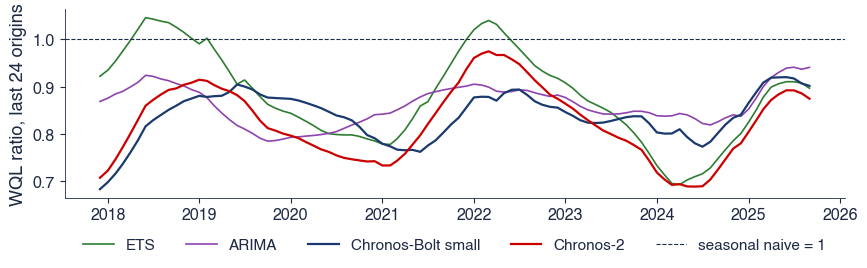

                     mase    wql  cov80  rel_mase  rel_wql
Seasonal naive      0.873  0.667  0.900     1.000    1.000
ETS                 0.808  0.589  0.836     0.926    0.883
ARIMA               0.780  0.581  0.873     0.893    0.870
Chronos-Bolt tiny   0.720  0.537  0.858     0.825    0.806
Chronos-Bolt small  0.744  0.549  0.846     0.852    0.824
Chronos-2           0.726  0.542  0.800     0.831    0.812
                    before   after
Seasonal naive       1.000   1.000
ETS                  0.884   0.882
ARIMA                0.851   0.885
Chronos-Bolt tiny    0.773   0.831
Chronos-Bolt small   0.772   0.862
Chronos-2            0.761   0.851
_n                  60.000  57.000


In [11]:
# Solution
b1 = b1_inflation(save_it=False)
print(pd.DataFrame(b1['table']).T.round(3))
print(pd.DataFrame({'before': b1['before'], 'after': b1['after']}).round(3))

**Interpretation of the result.** Relative WQL of Chronos-2: 0.812 overall, 0.761 before and 0.851 after January 2021; the gain shrinks after the inflation shock.

## B2 [Proposed]: error by horizon for US retail sales

**Question.** At which horizons does a zero-shot model help most, and does the size of the model matter? Model: B1.

1. Compute the MAE of each model at each step $j = 1, \dots, 12$.
2. Divide by the seasonal naive MAE and plot.
3. Compare the foundation models with ETS and ARIMA at $j = 1$ and $j = 12$.
4. Interpretation: why do the ratios rise towards 1?

**Report:** ten ratios, one figure, one sentence.

In [ ]:
# Your code here


## B3 [Solved]: is Chronos-2 significantly better?

1. For each series compute the per-origin WQL differences against ARIMA and the seasonal naive.
2. Compute the Diebold-Mariano statistics with a Newey-West variance.
3. Count the significant gains and losses.
4. Interpretation: does a better average WQL always mean a significant gain?

**Report:** fourteen DM statistics, two counts, one sentence.

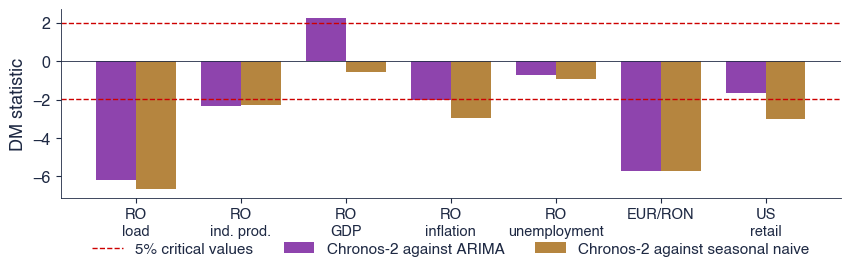

        ARIMA  Seasonal naive
load    -6.20           -6.67
ip      -2.32           -2.30
gdp      2.25           -0.54
infl    -2.00           -2.97
unemp   -0.72           -0.95
eurron  -5.71           -5.72
retail  -1.65           -3.01
{'_sig_better_ARIMA': 4, '_sig_worse_ARIMA': 1, '_sig_better_Seasonal naive': 5, '_sig_worse_Seasonal naive': 0}


In [13]:
# Solution
b3 = b3_dm(save_it=False)
print(pd.DataFrame({k: {r: round(v[r]['dm'], 2) for r in v} for k, v in b3.items() if not k.startswith('_')}).T)
print({k: v for k, v in b3.items() if k.startswith('_')})

**Interpretation of the result.** Chronos-2 is significantly better than ARIMA on 4 series and worse on 1 (Romanian GDP); on unemployment DM = -0.72.

# Part C: AI critique

## C1 [Proposed]: audit an AI answer

**Context.** An AI assistant summarised the backtest:

- (a) Chronos-2 beats every baseline on all seven series, so ARIMA is obsolete;
- (b) the WQL over several origins is the mean of the WQL of each origin;
- (c) an 80% interval that covers 73% of the hours is well calibrated;
- (d) MASE below 1 means the model beats the seasonal naive forecast on the test period;
- (e) zero-shot means the model never saw these series, so the backtest cannot be contaminated;
- (f) mean scaling lets one model forecast EUR/RON and an index of about 100 with the same tokens.

1. For each statement, say whether it is correct; if not, give the correct statement and the correct number.

**Report:** six verdicts with one line of justification each.

In [ ]:
# Your code here
